# Task 1 – Word Frequency Analysis

Which words appear most frequently across all SMS messages?

**Preprocessing applied before counting:**
- HTML-encoded placeholders (`&lt;#&gt;`, `&lt;URL&gt;`) → semantic tokens (`TOKEN_NUM`, `TOKEN_URL`)
- Real URLs → `TOKEN_URL`
- Lowercasing, punctuation removal, English stopword removal

In [2]:
from IPython.display import display
from pathlib import Path

from sms_analysis import load_dataset
from sms_analysis.analysis import word_frequencies
from sms_analysis.visualization import plot_word_frequencies, save_figure

DATASET = Path("../assignment/3D8026C4.zip/SMSSpamCollection")
OUTPUTS = Path("outputs")

dataset = load_dataset(DATASET)
print(dataset)

messages=[SMSMessage(label=<Label.HAM: 'ham'>, text='Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'), SMSMessage(label=<Label.HAM: 'ham'>, text='Ok lar... Joking wif u oni...'), SMSMessage(label=<Label.SPAM: 'spam'>, text="Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"), SMSMessage(label=<Label.HAM: 'ham'>, text='U dun say so early hor... U c already then say...'), SMSMessage(label=<Label.HAM: 'ham'>, text="Nah I don't think he goes to usf, he lives around here though"), SMSMessage(label=<Label.SPAM: 'spam'>, text="FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv"), SMSMessage(label=<Label.HAM: 'ham'>, text='Even my brother is not like to speak with me. They treat me like aids patent.'), SMSMessage(label=<Label.HAM:

## Top 20 words – all messages

In [3]:
df_all = word_frequencies(dataset.texts, top_n=50)
df_all

,word,count
0,token_num,3166
1,u,1373
2,your,681
3,call,593
4,s,562
5,now,499
6,t,459
7,m,424
8,ur,391
9,get,391


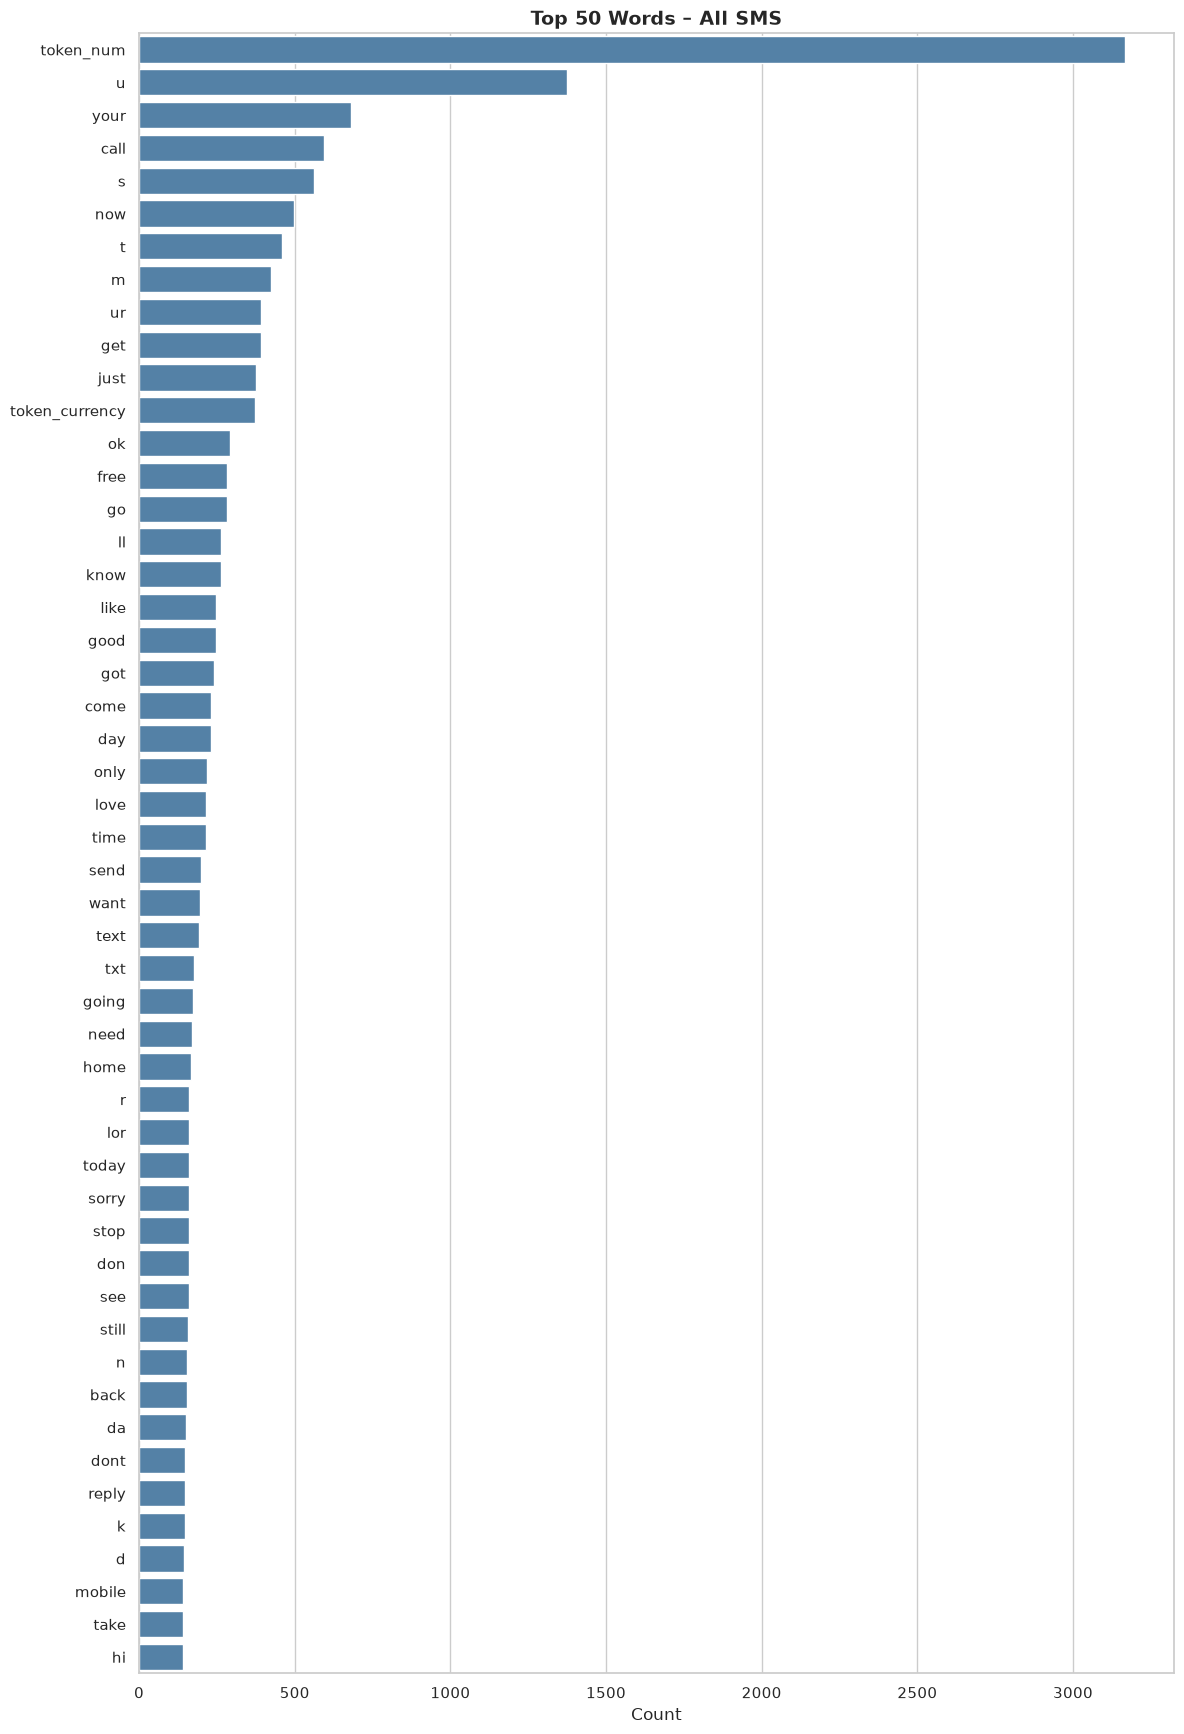

In [6]:
fig = plot_word_frequencies(df_all, title="Top 50 Words – All SMS")
display(fig)
save_figure(fig, OUTPUTS / "01_word_frequencies_all.png")

## Top words split by class

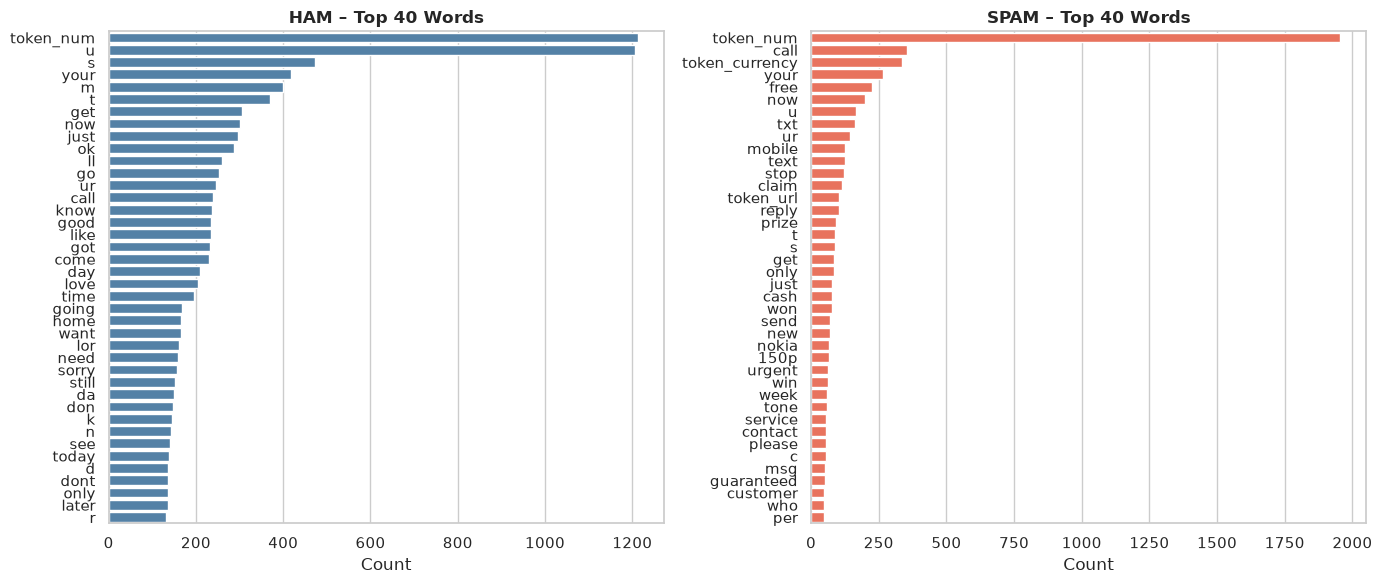

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

df_ham  = word_frequencies([m.text for m in dataset.ham],  top_n=40)
df_spam = word_frequencies([m.text for m in dataset.spam], top_n=40)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=df_ham,  x="count", y="word", ax=axes[0], color="steelblue")
sns.barplot(data=df_spam, x="count", y="word", ax=axes[1], color="tomato")
axes[0].set_title("HAM – Top 40 Words",  fontweight="bold")
axes[1].set_title("SPAM – Top 40 Words", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Count")
    ax.set_ylabel("")
plt.tight_layout()
display(fig)
save_figure(fig, OUTPUTS / "01_word_frequencies_by_class.png")

## Observations

- `token_num` is the most frequent token overall — numbers (prices, times, dates, counts)
  appear heavily in both classes after preprocessing.
- HAM is dominated by informal abbreviations typical for SMS: `u`, `ur`, `im`, `dont`, `ill`.
- SPAM introduces words like `free`, `call`, `token_url`, `prize`, `win` not prominent in HAM.
- These patterns are the basis for the HAM/SPAM vocabulary comparison in **Task 2**.